# Robust Watermarking for Telephony-Channel Audio Authentication
## Goal
Embed an imperceptible watermark into speech by modifying short-time frequency domain coefficients, then evaluate whether the watermark can still be detected after telephony-like distortions such as bandlimiting, noise, compression, quantization, and resampling.

## Imports
Load the numerical, plotting, audio, and notebook-display libraries used throughout the experiment.

In [759]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.fft as fft
import soundfile as sf
from IPython.display import Audio, display
from pathlib import Path
import librosa
import librosa.display

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

RNG = np.random.default_rng(123)

## Experiment configuration
Input file, frame geometry, watermark payload, embedding band, and channel distortion options.

In [760]:
# Global variables
#AUDIO_PATH = "data/SittingDownOutside2.wav" #BER 0
#AUDIO_PATH = "data/watermark_demo/clean/librispeech_04_speaker_6295_6.8s.wav" #2/3 sync BER 0.125, 1 0 0 0 1 1 1 0
#AUDIO_PATH = "data/watermark_demo/clean/librispeech_03_speaker_2803_6.1s.wav" #localizd correctly BER 0
#AUDIO_PATH = "data/watermark_demo/clean/librispeech_06_speaker_7850_6.0s.wav" #packet localization issue (1a)
#AUDIO_PATH = "data/watermark_demo/clean/librispeech_10_speaker_84_8.2s.wav" # BER 0
AUDIO_PATH = "data/MomAndBald.wav" #10101100 BER 0.125

# Framing
FRAME_MS = 20          # frame length in ms
HOP_MS = 10            # hop length in ms
NFFT = 1024

# Watermarking
EMBED_STRENGTH = 0.7
PREAMBLE_EMBED_STRENGTH = 1.5
BIT_REPEAT = 4
WATERMARK_BITS = np.array([1, 1, 0, 0, 1, 1, 0, 0], dtype=int)
WATERMARK_KEY_SEED = 12345
#13 bit Barker code
PREAMBLE_BITS = np.array(
    [1,1,1,1,1,0,0,1,1,0,1,0,1],
    dtype=int)
# Frequency bin selection
FREQ_LOW = 600         # Hz
FREQ_HIGH = 2500       # Hz

# Telephony-like channel settings
CHANNEL_BAND_LOW = 300     # Hz
CHANNEL_BAND_HIGH = 3400   # Hz
CHANNEL_TARGET_FS = 7500   # Hz, typical narrowband telephony sample rate
QUANT_BITS = 4

# Distortion toggles
APPLY_BANDLIMIT = False
APPLY_AWGN = False
APPLY_RESAMPLE = False
APPLY_QUANTIZATION = True

# Noise level
NOISE_STD = 0.005

# Carrier injection: constant band-limited noise added before embedding
# so energy-deficient (silent/pause) frames still have a floor for the
# spreading code to modulate.
CARRIER_AMPLITUDE = 0.000#8

# Detection: adaptive threshold — mean + PREAMBLE_SIGMA_GATE * std of corr landscape.
PREAMBLE_SIGMA_GATE = 3.0

# Minimum embedding delay enforced in experiments (seconds).
# Ensures the decoder cannot trivially find the preamble at frame 0.
MIN_EMBED_OFFSET_S = 0.5

# Shared protocol — everything both sides agree on before transmission.
# Encoder and decoder read from here; no encoder output is passed to the decoder.
PROTOCOL = {
    "preamble_bits": PREAMBLE_BITS,
    "payload_len":   len(WATERMARK_BITS),
    "checksum_len":  0,   # no checksum — lattice consistency used instead
    "repeat":        BIT_REPEAT,
    "key_seed":      WATERMARK_KEY_SEED,
    "nfft":          NFFT,
    "f_low":         FREQ_LOW,
    "f_high":        FREQ_HIGH,
    "frame_ms":      FRAME_MS,
    "hop_ms":        HOP_MS,
    "preamble_sigma_gate": PREAMBLE_SIGMA_GATE,
    "carrier_amplitude": CARRIER_AMPLITUDE,
}

## Helpers for audio processing

In [761]:
def load_audio(path):
    x, fs = sf.read(path)
    if x.ndim > 1:
        x = np.mean(x, axis=1)  # convert stereo to mono
    return x.astype(np.float64), fs

def normalize_audio(x, peak=0.99):
    m = np.max(np.abs(x))
    if m < 1e-12:
        return x.copy()
    return peak * x / m

def to_float64(x):
    return np.asarray(x, dtype=np.float64)

## Framing and reconstruction
Convert time values to samples, split audio into overlapping frames, and rebuild framed audio with overlap-add.

Time-domain audio is converted into overlapping short frames using

$$
L = \mathrm{round}\!\left(\frac{T_f}{1000} f_s\right), \qquad
H = \mathrm{round}\!\left(\frac{T_h}{1000} f_s\right), \qquad
M = 1 + \max\!\left(0, \left\lfloor\frac{N-L}{H}\right\rfloor\right)
$$

where $L$ is the frame length in samples, $H$ is the hop length, $M$ is the number of complete analysis frames returned by `frame_signal`, $N$ is the input length, $T_f$ is frame duration in milliseconds, $T_h$ is hop duration, and $f_s$ is the sample rate. Any trailing samples beyond the last complete frame are dropped.

Frame $m$ is

$$
x_m[n] = x[mH + n], \qquad 0 \le n < L, \quad 0 \le m < M.
$$

After inverse FFT, the notebook reconstructs with windowed overlap-add:

$$
y_{\mathrm{OLA}}[n] = \frac{\sum_{m=0}^{M-1} w[n-mH] \, \tilde{x}_m[n-mH]}{\sum_{m=0}^{M-1} w^2[n-mH]},
$$

for samples where the accumulated window-squared weight exceeds the code threshold `1e-7`; otherwise the output is set to zero. The embedder then crossfades the first and last frame-length region back to the host waveform:

$$
y[n] = (1-\lambda[n])x[n] + \lambda[n] y_{\mathrm{OLA}}[n], \qquad \lambda[n] = \frac{n}{L_f-1}, \quad 0 \le n < L_f,
$$

with the complementary fade applied over the final $L_f = \min(L, |x|, |y_{\mathrm{OLA}}|)$ samples.


In [762]:
def ms_to_samples(ms, fs):
    return int(round(ms * fs / 1000))

def frame_signal(x, frame_length, hop_length):
    num_frames = 1 + max(0, (len(x) - frame_length) // hop_length)
    frames = np.stack([
        x[i * hop_length : i * hop_length + frame_length]
        for i in range(num_frames)
    ], axis=0)
    return frames

def overlap_add(frames, hop_length, window=None):
    num_frames, frame_length = frames.shape
    out_len = (num_frames - 1) * hop_length + frame_length
    # output buffers
    y = np.zeros(out_len)
    wsum = np.zeros(out_len)

    if window is None:
        window = np.ones(frame_length)

    for i, frame in enumerate(frames):
        start = i * hop_length
        y[start:start + frame_length] += frame * window
        wsum[start:start + frame_length] += window**2

    # Avoid edge blow-ups where the Hann overlap weight is effectively zero.
    nz = wsum > 1e-7
    y[nz] /= wsum[nz]
    y[~nz] = 0.0
    return y

## Frequency-domain transforms
Create the analysis window, FFT frequency grid, bin mask, and STFT representation used by the embedder and detector.

### Windowing And STFT
A periodic Hann analysis window (`sym=False`) is applied to each frame:

$$
w[n] = \tfrac{1}{2}\left(1 - \cos\left(\frac{2\pi n}{L}\right)\right), \qquad 0 \le n < L.
$$

The windowed short-time spectrum for frame $m$ is

$$
X_m[k] = \sum_{n=0}^{L-1} x[mH+n] \, w[n] \, e^{-j 2\pi kn / N_{\mathrm{FFT}}}.
$$

The real FFT bin frequencies are

$$
f_k = \frac{k f_s}{N_{\mathrm{FFT}}}, \qquad 0 \le k \le \frac{N_{\mathrm{FFT}}}{2}.
$$

If $\mathcal{B} = \{k : f_{\mathrm{low}} \le f_k \le f_{\mathrm{high}}\}$ is the in-band bin set, the shared key keeps every other eligible bin,

$$
\mathcal{K} = \{\mathcal{B}_0, \mathcal{B}_2, \mathcal{B}_4, \ldots\},
$$

which matches `candidate_bins[::2]` in `derive_shared_key`.


In [763]:
# Create Hann window 
def get_window(frame_length):
    return signal.windows.hann(frame_length, sym=False)
# Get real frequency bins
def compute_fft_bins(fs, nfft):
    return np.fft.rfftfreq(nfft, d=1/fs)

def get_bin_mask(freqs, f_low, f_high): 
    return (freqs >= f_low) & (freqs <= f_high)
# STFT 
def stft_frames(x, fs, frame_ms=20, hop_ms=10, nfft=512):
    frame_len = ms_to_samples(frame_ms, fs)
    hop_len = ms_to_samples(hop_ms, fs)
    w = get_window(frame_len)

    frames = frame_signal(x, frame_len, hop_len)
    windowed = frames * w[None, :]
    X = np.fft.rfft(windowed, n=nfft, axis=1)
    freqs = compute_fft_bins(fs, nfft)

    return X, freqs, frame_len, hop_len, w

## Visualization helpers
Plot waveforms, single-frame spectra, and spectrograms.

In [764]:
def plot_waveform(x, fs, title="Waveform"):
    t = np.arange(len(x)) / fs
    plt.figure()
    plt.plot(t, x)
    plt.title(title)
    plt.xlabel("Time [s]")
    plt.ylabel("Amplitude")
    plt.show()

def plot_spectrum_of_frame(X_frame, freqs, title="Frame Spectrum"):
    plt.figure()
    plt.plot(freqs, np.abs(X_frame))
    plt.title(title)
    plt.xlabel("Frequency [Hz]")
    plt.ylabel("Magnitude")
    plt.show()

def plot_spectrogram(x, fs, title="Spectrogram"):
    f, t, Sxx = signal.spectrogram(x, fs=fs, nperseg=256, noverlap=128)
    plt.figure()
    plt.pcolormesh(t, f, 10*np.log10(Sxx + 1e-12), shading="gouraud")
    plt.title(title)
    plt.ylabel("Frequency [Hz]")
    plt.xlabel("Time [s]")
    plt.colorbar(label="Power [dB]")
    plt.ylim(0, 4000)
    plt.show()

def plot_codec_timeline(x, fs, metadata, title="Codec Timeline", max_packets=None, anchor="embed"):
    # Plot the waveform with colored packet regions overlaid.
    t = np.arange(len(x)) / fs
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, x, color="0.2", linewidth=0.8, alpha=0.85)

    frame_len = int(metadata["frame_len"])
    hop_len = int(metadata["hop_len"])
    packet_len = int(metadata["packet_symbol_len"])
    preamble_len = int(metadata["preamble_len"])
    payload_len = int(metadata["payload_len"] * metadata.get("payload_repeat", 1))
    checksum_len = int(metadata["checksum_len"] * metadata.get("checksum_repeat", 1))

    total_frames = max(0, 1 + (len(x) - frame_len) // hop_len)
    if anchor == "decode":
        decode_meta = metadata.get("last_decode", {})
        valid_starts = np.asarray(decode_meta.get("valid_packet_starts", []), dtype=int)
        packet_starts_meta = np.asarray(decode_meta.get("packet_starts", []), dtype=int)
        best_start = decode_meta.get("best_start")

        if len(valid_starts) > 0:
            base_start = int(np.min(valid_starts))
        elif best_start is not None:
            base_start = int(best_start)
        elif len(packet_starts_meta) > 0:
            base_start = int(np.min(packet_starts_meta))
        else:
            base_start = 0

        if total_frames >= base_start + packet_len:
            num_packets = 1 + (total_frames - base_start - packet_len) // packet_len
        else:
            num_packets = 0
        packet_starts = base_start + packet_len * np.arange(num_packets, dtype=int)
    else:
        base_start = int(metadata.get("embedding_start_frame", 0))
        num_packets = int(metadata.get("num_packets", 0))
        packet_starts = base_start + packet_len * np.arange(num_packets, dtype=int)

    if max_packets is not None:
        packet_starts = packet_starts[:int(max_packets)]

    regions = [
        ("Preamble", 0, preamble_len, "tab:red"),
        ("Watermark payload", preamble_len, preamble_len + payload_len, "tab:blue"),
    ]
    if checksum_len > 0:
        regions.append(
            ("Checksum", preamble_len + payload_len, preamble_len + payload_len + checksum_len, "tab:green")
        )

    used_labels = set()
    for packet_start in packet_starts:
        for label, rel_start, rel_stop, color in regions:
            start_frame = int(packet_start + rel_start)
            stop_frame = int(packet_start + rel_stop - 1)
            if stop_frame < start_frame:
                continue
            start_t = (start_frame * hop_len) / fs
            stop_t = (stop_frame * hop_len + frame_len) / fs
            if len(t) == 0 or start_t > t[-1]:
                continue
            legend_label = label if label not in used_labels else None
            ax.axvspan(start_t, min(stop_t, t[-1]), color=color, alpha=0.18, label=legend_label)
            used_labels.add(label)

    ax.set_title(title)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(0, t[-1] if len(t) else 0)
    ax.legend(loc="upper right")
    plt.show()

## Watermark symbols and frame selection
Expand the payload bits, map them to bipolar symbols, create the spreading key, and choose energetic frames for embedding.
Each bit will be stored by distributing a generated pattern across many bins in one frame of the singal. 

*This relies on the receiver knowing the spreading code.* 

So while this is great for avoiding perception as the watermark energy is spread across multiple bins, without an oracle for the decoder I need to find a reliable a codec protocol.
Embedding frames are chosen by energy content and proximity ot other bit embeddings. Chosen frames must meet a minimum threshold to avoid trying to embed information where there is no carrier. 

In [765]:
def repeat_bits(bits, repeat):
    return np.repeat(bits, repeat)
    
# Map bits to signed numbers: 0 -> -1, 1 -> +1
def bits_to_pm1(bits):
    return 2 * bits - 1  
    
# Generate pseudorandom spreading sequence
def make_spreading_code(num_bins, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return rng.choice([-1.0, 1.0], size=num_bins)


def compute_checksum_bits(payload_bits):
    # CRC-8 with polynomial 0x07 (x^8 + x^2 + x + 1).
    # False-accept probability = 1/256 vs 1/16 for the old 4-bit parity scheme.
    bits = np.asarray(payload_bits, dtype=int)
    data = int("".join(str(b) for b in bits), 2) if len(bits) else 0
    crc = 0
    for i in range(len(bits) - 1, -1, -1):
        bit = (data >> i) & 1
        if ((crc ^ (bit << 7)) & 0x80):
            crc = ((crc << 1) & 0xFF) ^ 0x07
        else:
            crc = (crc << 1) & 0xFF
    return np.array([(crc >> (7 - i)) & 1 for i in range(8)], dtype=int)

def derive_shared_key(fs, nfft=512, f_low=600, f_high=2500, key_seed=12345):
    freqs = compute_fft_bins(fs, nfft)
    bin_mask = get_bin_mask(freqs, f_low, f_high)
    candidate_bins = np.where(bin_mask)[0]
    selected_bins = candidate_bins[::2]

    key_rng = np.random.default_rng(key_seed)
    spreading_code = make_spreading_code(len(selected_bins), rng=key_rng)
    return freqs, selected_bins, spreading_code

## Watermark embedding
Embed repeated spread-spectrum symbols into high-energy speech frames.

The embedder now stores the shared `PROTOCOL` inside its returned runtime metadata so the notebook can separate:
- protocol values that a real receiver is allowed to know ahead of time, and
- diagnostics/runtime bookkeeping such as packet counts, detected starts, and plotting helpers.


### Spread-Spectrum Embedding
The current protocol packet is a Barker preamble followed by repeated payload bits (with checksum length set to zero in the active notebook configuration):

$$
\mathbf{b}_{\mathrm{pkt}} = \bigl[\mathbf{p},\, \mathrm{repeat}(\mathbf{b}, R)\bigr].
$$

Each packet symbol is then mapped from bits to bipolar values:

$$
b \in \{0,1\} \quad \rightarrow \quad s = 2b - 1 \in \{-1,+1\}.
$$

If the optional carrier floor is enabled, the embedder first adds deterministic band-passed noise

$$
x_{\mathrm{in}}[n] = x[n] + \eta[n],
$$

where $\eta[n]$ is seeded Gaussian noise filtered to the watermark band. For selected frequency bins $k \in \mathcal{K}$, the notebook perturbs only the magnitude and keeps phase unchanged. The active-bin mask is

$$
\mu_m[k] = \mathbf{1}\!\left\{|X_m[k]| > 0.05 \max_{u \in \mathcal{K}} |X_m[u]|\right\},
$$

and the frame-level embedding magnitude is

$$
A_m = \begin{cases}
\dfrac{\sum_{u \in \mathcal{K}} \mu_m[u] |X_m[u]|}{\sum_{u \in \mathcal{K}} \mu_m[u]}, & \text{if any active bins exist} \\
\dfrac{1}{|\mathcal{K}|} \sum_{u \in \mathcal{K}} |X_m[u]|, & \text{otherwise.}
\end{cases}
$$

The symbol strength depends on packet position,

$$
\alpha_m = \begin{cases}
\alpha_{\mathrm{pre}}, & m \text{ in the preamble} \\
\alpha, & m \text{ in the repeated payload,}
\end{cases}
$$

so the actual perturbation applied by the code is

$$
\Delta_m[k] = \alpha_m \, s_m \, c[k] \, A_m \, \mu_m[k],
$$

$$
|X'_m[k]| = \max\Bigl(0,\, |X_m[k]| + \Delta_m[k]\Bigr),
$$

$$
X'_m[k] = |X'_m[k]| e^{j \angle X_m[k]}.
$$

Here $c[k] \in \{-1,+1\}$ is the pseudorandom spreading code derived from the shared seed. After inverse FFT and overlap-add, the output waveform is peak-normalized.


In [766]:
def embed_spread_spectrum(
    x,
    fs,
    bits,
    frame_ms=20,
    hop_ms=10,
    nfft=512,
    f_low=600,
    f_high=2500,
    alpha=0.01,
    repeat=4,
    start_frame=0,
    rng=None
):
    if rng is None:
        rng = np.random.default_rng()

    protocol = dict(globals().get("PROTOCOL", {}))

    # Build the packet that will be streamed through the audio: a known
    # preamble for synchronization, repeated payload bits, and a repeated
    # checksum for rejecting bad packet detections.
    key_seed = protocol.get("key_seed", globals().get("WATERMARK_KEY_SEED", 12345))
    preamble_bits = np.asarray(
        protocol.get(
            "preamble_bits",
            globals().get("PREAMBLE_BITS", np.array([1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1], dtype=int)),
        ),
        dtype=int,
    )
    payload_bits = np.asarray(bits, dtype=int)
    preamble_alpha = float(globals().get("PREAMBLE_EMBED_STRENGTH", alpha))
    checksum_len_proto = int(protocol.get("checksum_len", 0))
    if checksum_len_proto > 0:
        checksum_bits = compute_checksum_bits(payload_bits)
    else:
        checksum_bits = np.array([], dtype=int)

    coded_payload_bits = repeat_bits(payload_bits, repeat)
    coded_checksum_bits = repeat_bits(checksum_bits, repeat)
    if checksum_len_proto > 0:
        packet_frame_bits = np.concatenate([
            preamble_bits,
            coded_payload_bits,
            coded_checksum_bits,
        ])
    else:
        packet_frame_bits = np.concatenate([preamble_bits, coded_payload_bits])
    packet_pm1 = bits_to_pm1(packet_frame_bits)

    # Carrier injection: add seeded band-limited noise to the signal so that
    # silent frames have a non-zero spectral floor for the spreading code to
    # modulate.  The carrier is deterministic (key_seed) and its amplitude is
    # read from the protocol so encoder and decoder share the same expectation.
    carrier_amplitude = float(
        protocol.get("carrier_amplitude",
                     globals().get("CARRIER_AMPLITUDE", 0.008))
    )
    if carrier_amplitude > 0:
        carrier_rng = np.random.default_rng(key_seed + 1)
        carrier_noise = carrier_rng.normal(0.0, carrier_amplitude, len(x))
        sos = signal.butter(4, [f_low, f_high], btype='bandpass', fs=fs, output='sos')
        carrier_noise = signal.sosfilt(sos, carrier_noise)
        x = x + carrier_noise

    # Analyze the speech in short overlapping frames. Each packet symbol is
    # embedded in one frame, so the packet timing is tied to the STFT hop size.
    frame_len = ms_to_samples(frame_ms, fs)
    hop_len = ms_to_samples(hop_ms, fs)
    w = get_window(frame_len)

    frames = frame_signal(x, frame_len, hop_len)
    X = np.fft.rfft(frames * w[None, :], n=nfft, axis=1)

    # Encoder and decoder share this deterministic key: same seed, same band,
    # same FFT size gives the same selected bins and spreading sequence.
    freqs, selected_bins, spreading_code = derive_shared_key(
        fs,
        nfft=nfft,
        f_low=f_low,
        f_high=f_high,
        key_seed=key_seed,
    )

    packet_symbol_len = len(packet_pm1)
    num_frames = X.shape[0]
    start_frame = int(np.clip(start_frame, 0, num_frames))
    available_frames = max(0, num_frames - start_frame)
    num_packets = available_frames // packet_symbol_len
    usable_frames = num_packets * packet_symbol_len

    print("Embed packet starts:")
    if num_packets == 0:
        print("  no complete packets fit in the available frame stream")
    else:
        for packet_idx in range(num_packets):
            packet_start = start_frame + packet_idx * packet_symbol_len
            packet_time_s = packet_start * hop_len / fs
            print(
                f"  packet {packet_idx}: start_frame={packet_start}, start_time={packet_time_s:.3f}s"
            )

    if usable_frames > 0:
        expanded_bits = np.tile(packet_frame_bits, num_packets)
        expanded_pm1 = np.tile(packet_pm1, num_packets)
    else:
        expanded_bits = np.array([], dtype=int)
        expanded_pm1 = np.array([], dtype=int)

    Xw = X.copy()

    for symbol_idx, symbol in enumerate(expanded_pm1):
        frame_idx = start_frame + symbol_idx
        mag = np.abs(Xw[frame_idx, selected_bins])
        phase = np.angle(Xw[frame_idx, selected_bins])
        symbol_in_packet = symbol_idx % packet_symbol_len
        symbol_alpha = preamble_alpha if symbol_in_packet < len(preamble_bits) else alpha

        # Only modify bins with meaningful speech energy.
        if np.max(mag) > 0:
            mask_local = mag > 0.05 * np.max(mag)
        else:
            mask_local = np.zeros_like(mag, dtype=bool)

        # Energy-normalized embedding: use the mean magnitude over active bins
        # rather than per-bin magnitude.  Every frame now contributes equal
        # embedded power regardless of spectral shape, making soft scores
        # uniform across the packet and easier to threshold reliably.
        frame_mag = np.mean(mag[mask_local]) if mask_local.any() else np.mean(mag)
        delta = symbol_alpha * symbol * spreading_code * frame_mag * mask_local
        mag_new = np.maximum(0.0, mag + delta)
        Xw[frame_idx, selected_bins] = mag_new * np.exp(1j * phase)

    # Convert the modified STFT frames back to audio with overlap-add.
    frames_w = np.fft.irfft(Xw, n=nfft, axis=1)[:, :frame_len]
    y = overlap_add(frames_w, hop_len, window=w)

    # Crossfade the endpoints back to the host signal to suppress the
    # large edge transient that can appear in the first/last frame.
    fade_len = min(frame_len, len(x), len(y))
    if fade_len > 1:
        fade_in = np.linspace(0.0, 1.0, fade_len)
        fade_out = np.linspace(1.0, 0.0, fade_len)
        y[:fade_len] = x[:fade_len] * (1.0 - fade_in) + y[:fade_len] * fade_in
        y[-fade_len:] = y[-fade_len:] * fade_out + x[-fade_len:] * (1.0 - fade_out)

    y = normalize_audio(y)

    metadata = {
        "protocol": protocol,
        "freqs": freqs,
        "expanded_bits": expanded_bits,
        "usable_frames": usable_frames,
        "frame_len": frame_len,
        "hop_len": hop_len,
        "window": w,
        "key_seed": key_seed,
        "nfft": nfft,
        "f_low": f_low,
        "f_high": f_high,
        "preamble_bits": preamble_bits,
        "payload_bits": payload_bits,
        "checksum_bits": checksum_bits,
        "preamble_embed_strength": preamble_alpha,
        "coded_payload_bits": coded_payload_bits,
        "coded_checksum_bits": coded_checksum_bits,
        "packet_bits": np.concatenate([preamble_bits, payload_bits, checksum_bits]),
        "packet_frame_bits": packet_frame_bits,
        "packet_symbol_len": packet_symbol_len,
        "embedding_start_frame": start_frame,
        "preamble_len": len(preamble_bits),
        "payload_len": len(payload_bits),
        "checksum_len": 0,
        "payload_repeat": repeat,
        "checksum_repeat": repeat,
        "num_packets": num_packets,
    }
    return y, metadata

## Watermark detection
The decoder now rebuilds its structural settings primarily from the shared `PROTOCOL`: frame/hop duration, FFT size, watermark band, repeat count, preamble, and key seed.

Runtime metadata is still kept for notebook diagnostics and visualization, but the core decode logic no longer needs embed-time oracle values such as selected bins or a stored spreading code.


### Detection And Synchronization
For each received frame, the decoder computes a soft score by correlating the centered spectral magnitudes with the shared spreading code:


$$
\rho_m = \frac{1}{|\mathcal{K}|} \sum_{k \in \mathcal{K}} \left(|Y_m[k]| - \frac{1}{|\mathcal{K}|}\sum_{u \in \mathcal{K}}|Y_m[u]|\right) c[k].
$$

The score stream is RMS-normalized across time,

$$
\tilde{\rho}_m = \frac{\rho_m}{\sqrt{\frac{1}{M} \sum_{q=0}^{M-1} \rho_q^2} + 10^{-12}},
$$

and the Barker preamble $p[i] \in \{-1,+1\}$ is detected with the zero-mean sliding correlation actually used in the code:

$$
\Gamma[t] = \sum_{i=0}^{L_p-1} \Bigl(\tilde{\rho}_{t+i} - \overline{\tilde{\rho}}_{t:t+L_p-1}\Bigr) \Bigl(p[i] - \overline{p}\Bigr).
$$

Candidate starts must exceed the adaptive gate

$$
\Gamma[t] \ge \mu_{\Gamma} + \kappa \sigma_{\Gamma},
$$

where $\kappa = \texttt{PREAMBLE\_SIGMA\_GATE}$, and non-maximum suppression prevents two candidates from landing within one packet length

$$
P = L_p + L_b R,
$$

where $L_b$ is the number of payload bits and $R$ is the per-bit repeat count.

Among the surviving candidates, the receiver picks the lattice anchor with the largest accumulated preamble energy,

$$
E(a) = \sum_{q \in \mathbb{Z}\setminus\{0\}} \max_{|\delta| \le F} \Gamma[a + qP + \delta], \qquad F = \left\lfloor\frac{L_p}{2}\right\rfloor,
$$

and keeps only starts that lie within $\pm F$ frames of that packet lattice. For each accepted start, fine alignment searches the offsets $\delta \in [-F,F]$ in descending correlation order, then repeated payload symbols are combined by summation:

$$
\beta_j^{(t)} = \sum_{r=0}^{R-1} \rho_{t + \delta + L_p + jR + r}.
$$

The per-packet hard decision is

$$
\hat{b}_j^{(t)} = \begin{cases}
1, & \beta_j^{(t)} > 0 \\
0, & \beta_j^{(t)} \le 0.
\end{cases}
$$

Finally, if $Q$ packet decodes survive, the notebook takes a majority vote across packets:

$$
\hat{b}_j = \mathbf{1}\!\left\{\frac{1}{Q} \sum_{q=1}^{Q} \hat{b}_j^{(q)} \ge 0.5\right\}.
$$

If no packet survives the lattice stage, the fallback start is simply $\arg\max_t \Gamma[t]$. In the current active protocol, acceptance is driven by lattice consistency and in-bounds fine alignment rather than checksum validation because `checksum_len = 0`.




In [767]:
def decode_spread_spectrum(
    y,
    fs,
    metadata,
    frame_ms=20,
    hop_ms=10,
    nfft=512,
    repeat=4
):
    protocol = metadata.get("protocol", globals().get("PROTOCOL", {}))

    frame_len = metadata.get("frame_len", ms_to_samples(protocol.get("frame_ms", frame_ms), fs))
    hop_len = metadata.get("hop_len", ms_to_samples(protocol.get("hop_ms", hop_ms), fs))
    nfft = int(protocol.get("nfft", metadata.get("nfft", nfft)))
    key_seed = protocol.get("key_seed", metadata.get("key_seed", globals().get("WATERMARK_KEY_SEED", 12345)))
    preamble_bits = np.asarray(protocol.get("preamble_bits", metadata["preamble_bits"]), dtype=int)
    payload_len = int(protocol.get("payload_len", metadata["payload_len"]))
    payload_repeat = int(protocol.get("repeat", metadata.get("payload_repeat", repeat)))
    f_low = protocol.get("f_low", metadata.get("f_low", globals().get("FREQ_LOW", 600)))
    f_high = protocol.get("f_high", metadata.get("f_high", globals().get("FREQ_HIGH", 2500)))
    sigma_gate = float(
        protocol.get("preamble_sigma_gate",
                     globals().get("PREAMBLE_SIGMA_GATE", 3.0))
    )

    frames = frame_signal(y, frame_len, hop_len)
    w = get_window(frame_len)
    Y = np.fft.rfft(frames * w[None, :], n=nfft, axis=1)

    _, selected_bins, spreading_code = derive_shared_key(
        fs, nfft=nfft, f_low=f_low, f_high=f_high, key_seed=key_seed,
    )

    scores = np.array([
        np.dot(np.abs(Y[m, selected_bins]) - np.mean(np.abs(Y[m, selected_bins])),
               spreading_code) / len(selected_bins)
        for m in range(Y.shape[0])
    ])

    score_rms = np.sqrt(np.mean(scores ** 2)) + 1e-12
    norm_scores = scores / score_rms

    preamble_pm1 = bits_to_pm1(preamble_bits)
    preamble_len = len(preamble_bits)
    payload_symbol_len = payload_len * payload_repeat
    packet_symbol_len = preamble_len + payload_symbol_len

    if len(scores) < packet_symbol_len:
        metadata["last_decode"] = {
            "packet_starts": np.array([], dtype=int),
            "valid_packet_starts": np.array([], dtype=int),
            "best_start": None,
            "checksum_ok": False,
            "preamble_corr": np.array([], dtype=float),
        }
        return np.array([], dtype=int), np.array([], dtype=float), scores

    preamble_pm1_zm = preamble_pm1 - preamble_pm1.mean()

    n_corr = len(norm_scores) - preamble_len + 1
    preamble_corr = np.empty(n_corr)
    for i in range(n_corr):
        win = norm_scores[i:i + preamble_len]
        preamble_corr[i] = np.dot(win - win.mean(), preamble_pm1_zm)

    corr_mean = preamble_corr.mean()
    corr_std = preamble_corr.std() + 1e-12
    min_corr = corr_mean + sigma_gate * corr_std

    # Collect all candidates above the adaptive threshold (NMS at packet_symbol_len).
    candidate_order = np.argsort(preamble_corr)[::-1]
    candidate_starts = []
    for start in candidate_order:
        if preamble_corr[start] < min_corr:
            break
        if any(abs(start - prev) < packet_symbol_len for prev in candidate_starts):
            continue
        candidate_starts.append(int(start))
        if len(candidate_starts) >= max(1, metadata.get("num_packets", 1) * 2):
            break

    # Lattice filtering: every genuine packet must land at
    #   anchor + k * packet_symbol_len  (± fine_range frames).
    # False-positive peaks from noise almost never satisfy this constraint.
    # Anchor is chosen by lattice energy: walk the full audio at
    # packet_symbol_len spacing from each candidate and sum the best local
    # preamble correlation in a ±fine_range window at each grid point.
    # The true anchor accumulates real preamble peaks from all embedded
    # packets; a false anchor lands on silence and scores near zero.
    fine_range = preamble_len // 2

    def _lattice_energy(anchor):
        total = 0.0
        # scan backward then forward from anchor
        for direction in (-1, 1):
            pos = anchor + direction * packet_symbol_len
            while 0 <= pos < len(preamble_corr):
                lo = max(0, pos - fine_range)
                hi = min(len(preamble_corr), pos + fine_range + 1)
                total += float(np.max(preamble_corr[lo:hi]))
                pos += direction * packet_symbol_len
        return total

    if candidate_starts:
        # Pick the anchor whose lattice accumulates the most preamble energy.
        anchor = max(candidate_starts, key=_lattice_energy)
        lattice_starts = []
        for s in candidate_starts:
            phase = (s - anchor) % packet_symbol_len
            on_lattice = (phase <= fine_range or phase >= packet_symbol_len - fine_range)
            if on_lattice:
                lattice_starts.append(s)
        candidate_starts = lattice_starts

    def _decode_from(aligned):
        p_start = aligned + preamble_len
        p_stop  = p_start + payload_symbol_len
        if p_stop > len(scores) or aligned < 0:
            return None
        p_sc = scores[p_start:p_stop]
        p_bit_sc = np.array([
            np.sum(p_sc[i * payload_repeat:(i + 1) * payload_repeat])
            for i in range(payload_len)
        ])
        return {"payload": (p_bit_sc > 0).astype(int), "scores": p_bit_sc}

    valid_payloads = []
    valid_payload_scores = []
    valid_packet_starts = []
    candidate_debug = []

    for start in candidate_starts:
        # Fine-alignment: try ±preamble_len//2 offsets ordered by correlation.
        offsets = sorted(range(-fine_range, fine_range + 1), key=lambda d: -(
            preamble_corr[start + d] if 0 <= start + d < len(preamble_corr) else -np.inf
        ))
        best = None
        for delta in offsets:
            result = _decode_from(start + delta)
            if result is not None:
                if best is None:
                    best = {**result, "delta": delta, "aligned": start + delta}
                break   # take highest-correlation alignment

        raw = _decode_from(start) or {"payload": np.zeros(payload_len, int), "scores": np.zeros(payload_len)}
        display_start = best["aligned"] if best else start
        candidate_debug.append((
            int(start), int(display_start),
            float(display_start * hop_len / fs),
            "".join(str(b) for b in (best["payload"] if best else raw["payload"])),
            best is not None,
        ))

        if best:
            valid_payloads.append(best["payload"])
            valid_payload_scores.append(best["scores"])
            valid_packet_starts.append(best["aligned"])

    for raw_start, aligned_start, t, pb, ok in sorted(candidate_debug, key=lambda r: r[0]):
        delta = aligned_start - raw_start
        delta_str = f" Δ={delta:+d}" if delta != 0 else ""
        print(f"Decode candidate: raw_frame={raw_start}{delta_str}, "
              f"start_time={t:.3f}s, payload_bits={pb}, lattice_ok={ok}")

    if valid_payloads:
        payload_matrix = np.stack(valid_payloads, axis=0)
        score_matrix   = np.stack(valid_payload_scores, axis=0)
        decoded_bits   = (np.mean(payload_matrix, axis=0) >= 0.5).astype(int)
        bit_scores     = np.mean(score_matrix, axis=0)
        best_start     = int(valid_packet_starts[0])
        checksum_ok    = True
        print(f"Decode accepted starts: {valid_packet_starts}")
        print(f"Decode final bits:      {''.join(str(int(b)) for b in decoded_bits)}")
    else:
        best_start  = int(np.argmax(preamble_corr))
        p_start     = best_start + preamble_len
        p_sc        = scores[p_start:p_start + payload_symbol_len]
        num_bits    = len(p_sc) // payload_repeat
        bit_scores  = np.array([
            np.sum(p_sc[i * payload_repeat:(i + 1) * payload_repeat])
            for i in range(num_bits)
        ])
        decoded_bits        = (bit_scores > 0).astype(int)
        valid_packet_starts = np.array([], dtype=int)
        checksum_ok         = False
        print(f"Decode fallback: start_frame={best_start}, "
              f"start_time={best_start * hop_len / fs:.3f}s, "
              f"bits={''.join(str(int(b)) for b in decoded_bits)}")

    metadata["last_decode"] = {
        "packet_starts": np.array(candidate_starts, dtype=int),
        "valid_packet_starts": np.array(valid_packet_starts, dtype=int),
        "best_start": best_start,
        "checksum_ok": checksum_ok,
        "preamble_corr": preamble_corr,
        "preamble_corr_threshold": min_corr,
        "preamble_end_index": None if best_start is None else best_start + preamble_len,
    }

    return decoded_bits, bit_scores, scores

# Distortion
Apply optional telephony-like distortions so robustness can be tested under bandlimiting, noise, resampling, or quantization.

For a narrowband telephone path, the realistic reference point is usually:
- sample rate near `8 kHz`
- useful speech band near `300–3400 Hz`
- optional companding/quantization noise and codec artifacts

In the current notebook, that bottleneck is approximated with a `7.5 kHz` resampling round-trip plus optional `4`-bit quantization, so it is still fine to start from `16 kHz` or `44.1 kHz` source files as long as the channel stage enforces the narrowband degradation before decoding.


### Telephony Channel Model
The notebook's channel block applies enabled impairments in the code order: bandlimit, AWGN, resample round-trip, quantization, then peak normalization. The active narrowband parameters are

$$
300\ \text{Hz} \lesssim f \lesssim 3400\ \text{Hz}, \qquad f_s^{(\mathrm{channel})} = 7.5\ \text{kHz}, \qquad B = 4\ \text{bits}.
$$

The resampling stage models an encoder/decoder bottleneck

$$
x[n] \xrightarrow[]{f_s \rightarrow 7500} x_{7.5k}[n] \xrightarrow[]{7500 \rightarrow f_s} \tilde{x}[n],
$$

the optional additive-noise stage is

$$
x_{\mathrm{awgn}}[n] = x[n] + \nu[n], \qquad \nu[n] \sim \mathcal{N}(0, \sigma^2),
$$

and the uniform quantizer is

$$
N_q = 2^B, \qquad x_q[n] = \frac{2}{N_q-1} \operatorname{round}\!\left(\frac{(x[n] + 1)(N_q-1)}{2}\right) - 1.
$$

This lets the original file stay at `16 kHz` or `44.1 kHz` while the channel stage still enforces telephone-like bandwidth, Nyquist loss, and coarse amplitude resolution before decoding.


In [768]:
def apply_bandlimit(x, fs, low=CHANNEL_BAND_LOW, high=CHANNEL_BAND_HIGH, order=6):
    sos = signal.butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
    return signal.sosfilt(sos, x)

def apply_awgn(x, std=0.003, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return x + rng.normal(0, std, size=len(x))

def apply_resample_roundtrip(x, fs, target_fs=CHANNEL_TARGET_FS):
    if fs == target_fs:
        return x.copy(), fs
    gcd = np.gcd(fs, target_fs)
    up = target_fs // gcd
    down = fs // gcd
    y = signal.resample_poly(x, up, down)
    z = signal.resample_poly(y, down, up)
    return z, fs

def apply_uniform_quantization(x, bits=QUANT_BITS):
    x = normalize_audio(x)
    levels = 2**bits
    xq = np.round((x + 1) * (levels - 1) / 2)
    xq = 2 * xq / (levels - 1) - 1
    return xq

def apply_test_channel(x, fs, rng=None):
    y = x.copy()

    if APPLY_BANDLIMIT:
        y = apply_bandlimit(y, fs)

    if APPLY_AWGN:
        y = apply_awgn(y, NOISE_STD, rng=rng)

    if APPLY_RESAMPLE:
        y, _ = apply_resample_roundtrip(y, fs, target_fs=CHANNEL_TARGET_FS)

    if APPLY_QUANTIZATION:
        y = apply_uniform_quantization(y, bits=QUANT_BITS)

    return normalize_audio(y)


## Evaluation metrics
Compute waveform error, SNR, and bit error rate for the watermarked and received signals.

In [769]:
def mse(x, y):
    n = min(len(x), len(y))
    return np.mean((x[:n] - y[:n])**2)

def snr_db(reference, test):
    n = min(len(reference), len(test))
    ref = reference[:n]
    err = ref - test[:n]
    p_ref = np.mean(ref**2) + 1e-12
    p_err = np.mean(err**2) + 1e-12
    return 10 * np.log10(p_ref / p_err)

def bit_error_rate(bits_true, bits_hat):
    n = min(len(bits_true), len(bits_hat))
    if n == 0:
        return np.nan
    return np.mean(bits_true[:n] != bits_hat[:n])

## Load audio and embed watermark
Read the source speech, show the original signal, embed the configured payload, and inspect the watermarked result.

Sample rate: 44100 Hz
Duration: 6.68 s


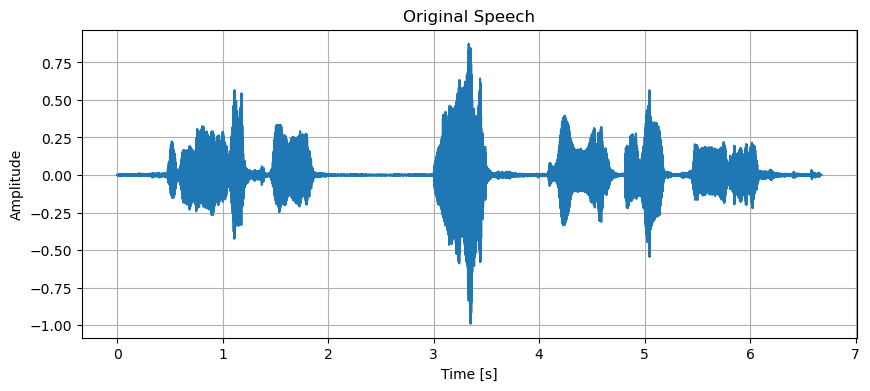

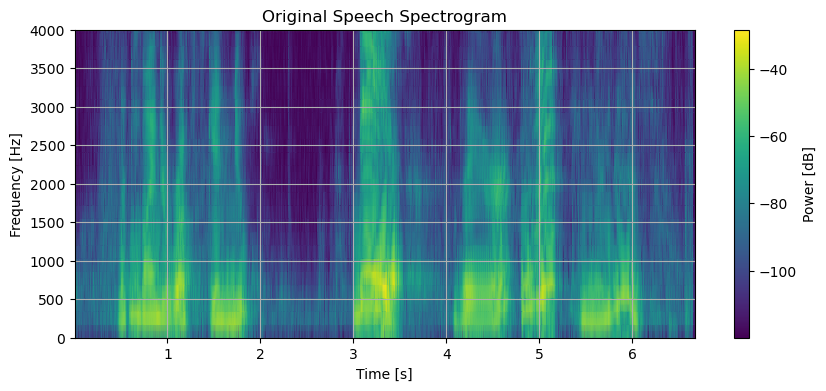

Embedding starts at 0.541 s  (frame 54)
Embed packet starts:
  packet 0: start_frame=54, start_time=0.540s
  packet 1: start_frame=99, start_time=0.990s
  packet 2: start_frame=144, start_time=1.440s
  packet 3: start_frame=189, start_time=1.890s
  packet 4: start_frame=234, start_time=2.340s
  packet 5: start_frame=279, start_time=2.790s
  packet 6: start_frame=324, start_time=3.240s
  packet 7: start_frame=369, start_time=3.690s
  packet 8: start_frame=414, start_time=4.140s
  packet 9: start_frame=459, start_time=4.590s
  packet 10: start_frame=504, start_time=5.040s
  packet 11: start_frame=549, start_time=5.490s
  packet 12: start_frame=594, start_time=5.940s
Saved watermarked audio: data/MomAndBald_watermarked.wav
Watermarked speech:


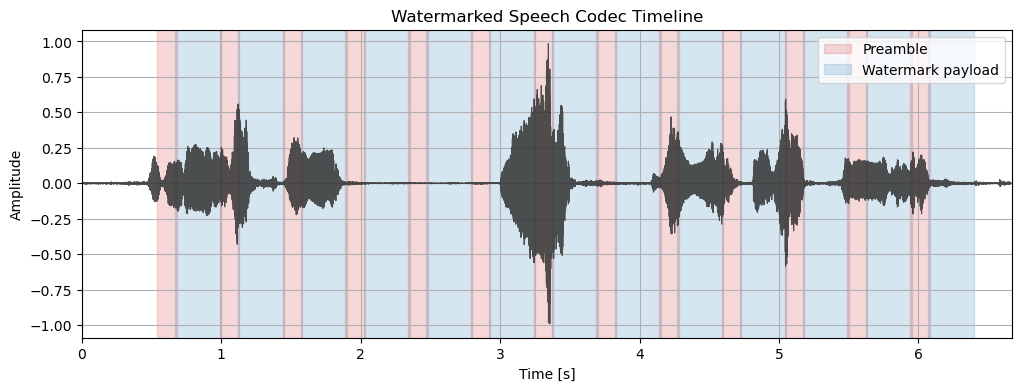

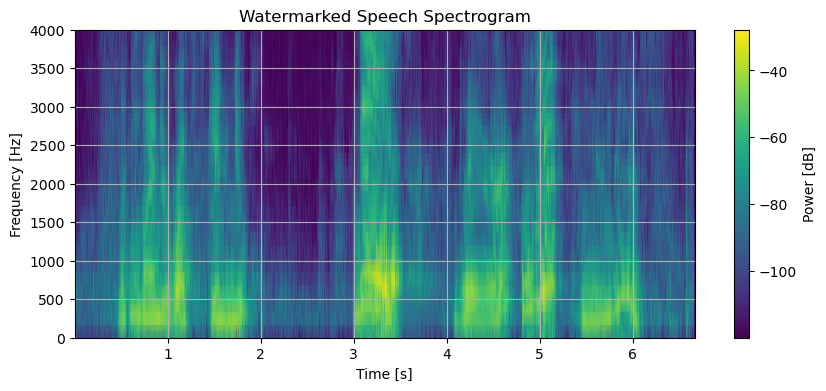

Watermark embedding SNR: 10.521821147242727


In [770]:
# Load speech
x, fs = load_audio(AUDIO_PATH)
x = normalize_audio(x)

print(f"Sample rate: {fs} Hz")
print(f"Duration: {len(x)/fs:.2f} s")

output_dir = Path("data")
output_dir.mkdir(exist_ok=True)
audio_stem = Path(AUDIO_PATH).stem
watermarked_audio_path = output_dir / f"{audio_stem}_watermarked.wav"
watermark_signature_path = output_dir / f"{audio_stem}_watermark_signature.wav"
received_audio_path = output_dir / f"{audio_stem}_received.wav"

display(Audio(x, rate=fs))
plot_waveform(x, fs, "Original Speech")
plot_spectrogram(x, fs, "Original Speech Spectrogram")

# Embed watermark at a random start in [200 ms, 700 ms].
# This models realistic unknown transmission delay and prevents the decoder
# from trivially finding the preamble at frame 0.
_hop_len = ms_to_samples(HOP_MS, fs)
_start_s = float(RNG.uniform(0.2, 0.7))
embed_start_frame = int(_start_s * fs / _hop_len)
print(f"Embedding starts at {_start_s:.3f} s  (frame {embed_start_frame})")

y_wm, meta = embed_spread_spectrum(
    x=x,
    fs=fs,
    bits=WATERMARK_BITS,
    frame_ms=FRAME_MS,
    hop_ms=HOP_MS,
    nfft=NFFT,
    f_low=FREQ_LOW,
    f_high=FREQ_HIGH,
    alpha=EMBED_STRENGTH,
    repeat=BIT_REPEAT,
    start_frame=embed_start_frame,
    rng=RNG
)

sf.write(watermarked_audio_path, y_wm, fs)
print(f"Saved watermarked audio: {watermarked_audio_path}")

print("Watermarked speech:")
display(Audio(y_wm, rate=fs))
plot_codec_timeline(y_wm, fs, meta, "Watermarked Speech Codec Timeline")
plot_spectrogram(y_wm, fs, "Watermarked Speech Spectrogram")

print("Watermark embedding SNR:", snr_db(x, y_wm))

Saved watermark signature audio: data/MomAndBald_watermark_signature.wav
Watermark Signature Audio:


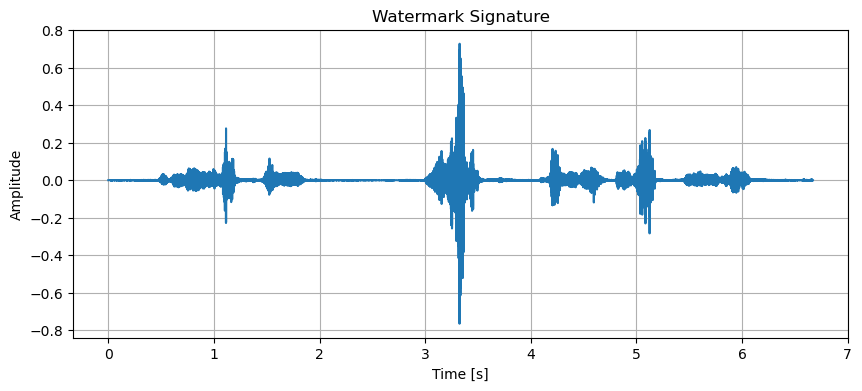

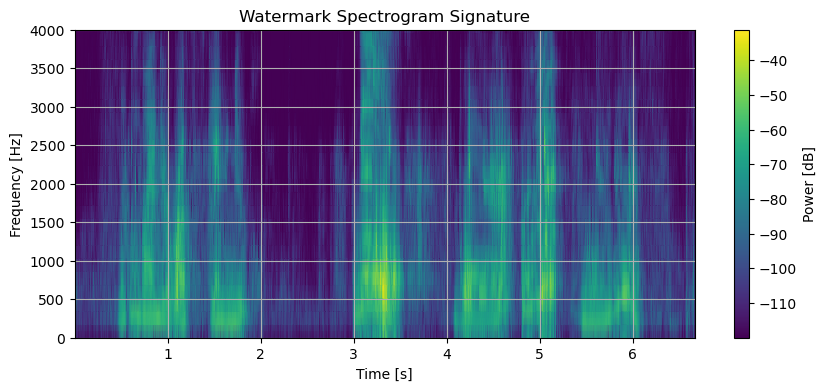

Watermark energy signature: [ 0.          0.          0.         ... -0.00026218 -0.00026218
 -0.00026218]


In [771]:
n = min(len(x), len(y_wm))
wmsig = x[:n] - y_wm[:n]

sf.write(watermark_signature_path, wmsig, fs)
print(f"Saved watermark signature audio: {watermark_signature_path}")

print("Watermark Signature Audio:")
display(Audio(wmsig, rate=fs))
plot_waveform(wmsig, fs, "Watermark Signature")
plot_spectrogram(wmsig, fs, "Watermark Spectrogram Signature")
print("Watermark energy signature:", (wmsig))

## Distort and decode
Pass the watermarked audio through the test channel, decode the payload, and report the recovered bits and BER.

Saved received audio: data/MomAndBald_received.wav
Received / distorted speech:


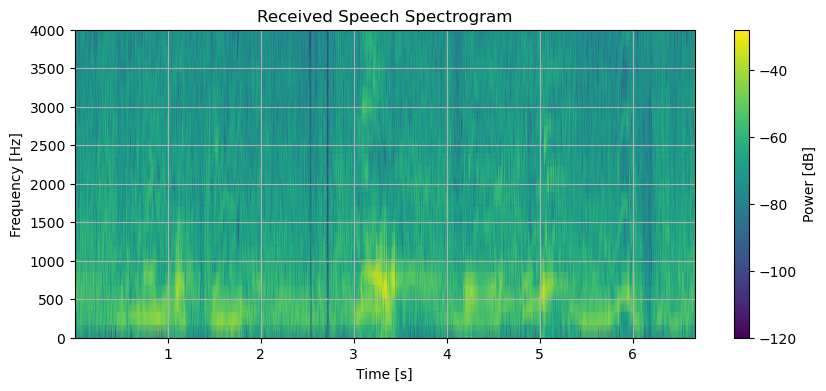

Decode candidate: raw_frame=324, start_time=3.240s, payload_bits=11010100, lattice_ok=True
Decode candidate: raw_frame=504, start_time=5.040s, payload_bits=00001000, lattice_ok=True
Decode accepted starts: [324, 504]
Decode final bits:      11011100


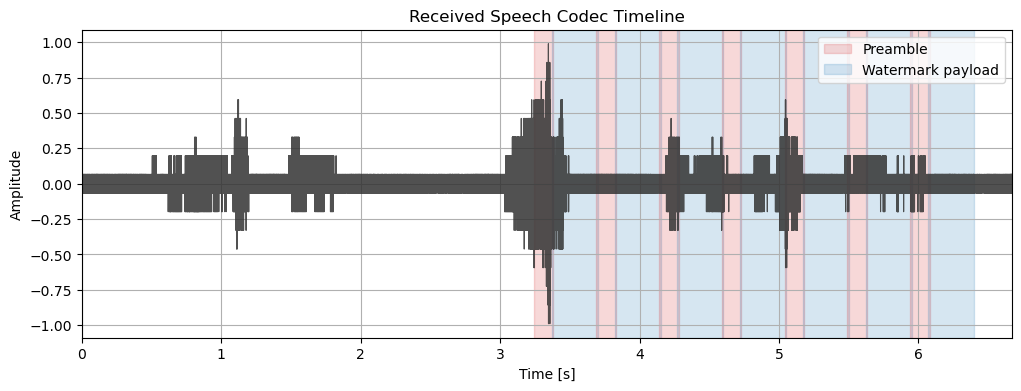

True bits:    [1 1 0 0 1 1 0 0]
Decoded bits: [1 1 0 1 1 1 0 0]
BER: 0.125


In [772]:
# Apply telephony-like channel
y_rx = apply_test_channel(y_wm, fs, rng=RNG)

sf.write(received_audio_path, y_rx, fs)
print(f"Saved received audio: {received_audio_path}")

print("Received / distorted speech:")
display(Audio(y_rx, rate=fs))
plot_spectrogram(y_rx, fs, "Received Speech Spectrogram")

# Decode
decoded_bits, bit_scores, frame_scores = decode_spread_spectrum(
    y=y_rx,
    fs=fs,
    metadata=meta,
    frame_ms=FRAME_MS,
    hop_ms=HOP_MS,
    nfft=NFFT,
    repeat=BIT_REPEAT
)

plot_codec_timeline(y_rx, fs, meta, "Received Speech Codec Timeline", anchor="decode")

print("True bits:   ", WATERMARK_BITS)
print("Decoded bits:", decoded_bits[:len(WATERMARK_BITS)])
print("BER:", bit_error_rate(WATERMARK_BITS, decoded_bits[:len(WATERMARK_BITS)]))

## Single-frame FFT watermark inspection
Look at one analysis frame before and after the spread-spectrum magnitude perturbation. The highlighted bins are regenerated from the shared protocol key and are the frequency bins used to carry each watermark symbol.

### Raw frame FFT
Select one frame from the embedded packet stream, compute its windowed FFT, and mark the spread-spectrum bins that the watermarking scheme will use.

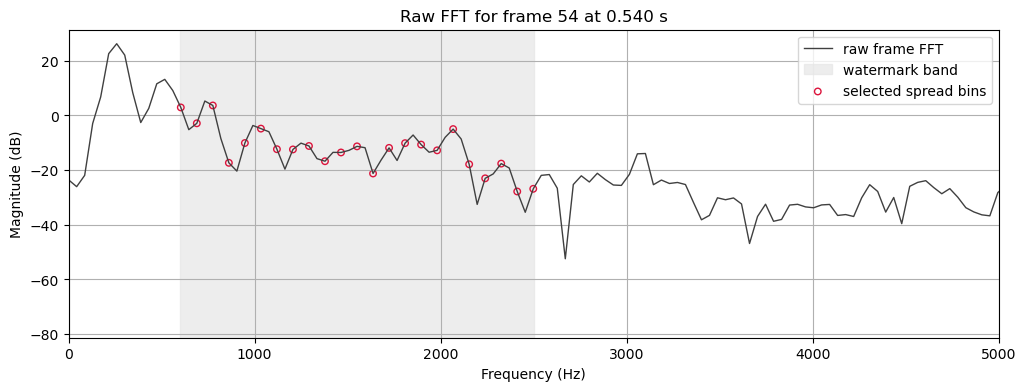

Frame index: 54
Frame start: 0.540 s
Selected spread-spectrum bins: 23


In [773]:
# Pick one frame from the first embedded packet and inspect its spectrum.
inspect_frame_idx = int(meta.get("embedding_start_frame", 0))
frame_len = int(meta["frame_len"])
hop_len = int(meta["hop_len"])
nfft_inspect = int(meta.get("nfft", NFFT))
f_low_inspect = float(meta.get("f_low", FREQ_LOW))
f_high_inspect = float(meta.get("f_high", FREQ_HIGH))
key_seed_inspect = int(meta.get("key_seed", WATERMARK_KEY_SEED))

frame_start = inspect_frame_idx * hop_len
raw_frame = x[frame_start:frame_start + frame_len]
if len(raw_frame) < frame_len:
    raw_frame = np.pad(raw_frame, (0, frame_len - len(raw_frame)))

w_inspect = get_window(frame_len)
freqs_inspect, selected_bins_inspect, spreading_code_inspect = derive_shared_key(
    fs,
    nfft=nfft_inspect,
    f_low=f_low_inspect,
    f_high=f_high_inspect,
    key_seed=key_seed_inspect,
)

X_raw_frame = np.fft.rfft(raw_frame * w_inspect, n=nfft_inspect)
raw_mag_db = 20 * np.log10(np.maximum(np.abs(X_raw_frame), 1e-12))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(freqs_inspect, raw_mag_db, color="0.25", linewidth=1.0, label="raw frame FFT")
ax.axvspan(f_low_inspect, f_high_inspect, color="0.9", alpha=0.7, label="watermark band")
ax.scatter(
    freqs_inspect[selected_bins_inspect],
    raw_mag_db[selected_bins_inspect],
    s=22,
    facecolors="none",
    edgecolors="crimson",
    linewidths=1.0,
    label="selected spread bins",
)
ax.set_xlim(0, min(fs / 2, max(5000, f_high_inspect + 500)))
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_title(f"Raw FFT for frame {inspect_frame_idx} at {frame_start / fs:.3f} s")
ax.legend(loc="best")
plt.show()

print(f"Frame index: {inspect_frame_idx}")
print(f"Frame start: {frame_start / fs:.3f} s")
print(f"Selected spread-spectrum bins: {len(selected_bins_inspect)}")

### Same frame with one watermark symbol applied
Apply the encoder's magnitude update to that frame only, using the packet symbol that belongs at this frame position, then compare the raw and marked spectra.

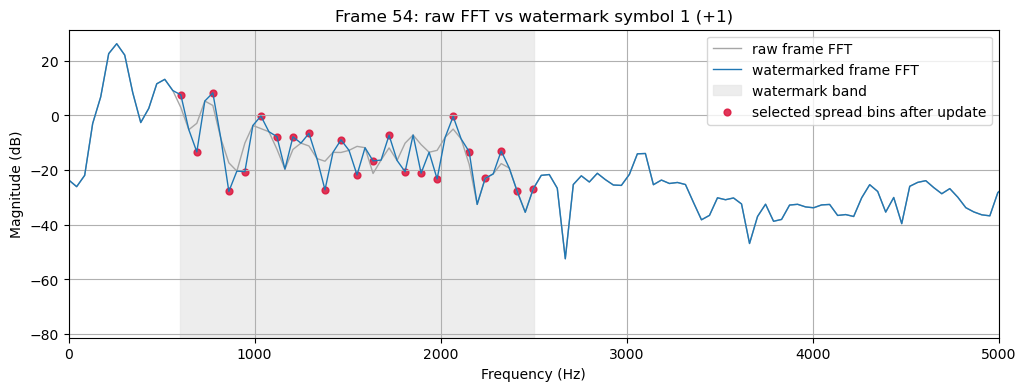

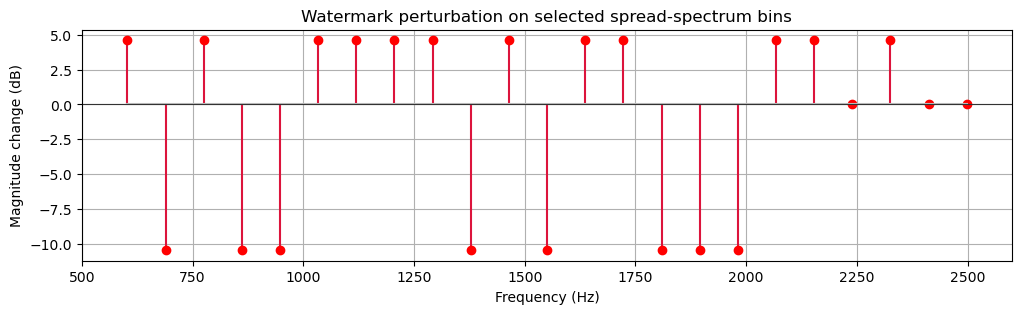

Packet-relative symbol index: 0
Watermark bit in this frame: 1
Signed symbol: +1


In [774]:
packet_frame_bits = np.asarray(meta["packet_frame_bits"], dtype=int)
packet_symbol_len = int(meta["packet_symbol_len"])
relative_symbol_idx = (inspect_frame_idx - int(meta.get("embedding_start_frame", 0))) % packet_symbol_len
inspect_bit = int(packet_frame_bits[relative_symbol_idx])
inspect_symbol = int(bits_to_pm1(np.array([inspect_bit]))[0])

X_marked_frame = X_raw_frame.copy()
marked_mag = np.abs(X_marked_frame[selected_bins_inspect])
marked_phase = np.angle(X_marked_frame[selected_bins_inspect])

if np.max(marked_mag) > 0:
    mask_local = marked_mag > 0.05 * np.max(marked_mag)
else:
    mask_local = np.zeros_like(marked_mag, dtype=bool)

frame_mag_inspect = np.mean(marked_mag[mask_local]) if mask_local.any() else np.mean(marked_mag)
marked_delta = EMBED_STRENGTH * inspect_symbol * spreading_code_inspect * frame_mag_inspect * mask_local
marked_mag_new = np.maximum(0.0, marked_mag + marked_delta)
X_marked_frame[selected_bins_inspect] = marked_mag_new * np.exp(1j * marked_phase)

marked_mag_db = 20 * np.log10(np.maximum(np.abs(X_marked_frame), 1e-12))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(freqs_inspect, raw_mag_db, color="0.65", linewidth=1.0, label="raw frame FFT")
ax.plot(freqs_inspect, marked_mag_db, color="tab:blue", linewidth=1.0, label="watermarked frame FFT")
ax.axvspan(f_low_inspect, f_high_inspect, color="0.9", alpha=0.7, label="watermark band")
ax.scatter(
    freqs_inspect[selected_bins_inspect],
    marked_mag_db[selected_bins_inspect],
    s=24,
    color="crimson",
    alpha=0.85,
    label="selected spread bins after update",
)
ax.set_xlim(0, min(fs / 2, max(5000, f_high_inspect + 500)))
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (dB)")
ax.set_title(f"Frame {inspect_frame_idx}: raw FFT vs watermark symbol {inspect_bit} ({inspect_symbol:+d})")
ax.legend(loc="best")
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
ax.stem(
    freqs_inspect[selected_bins_inspect],
    marked_mag_db[selected_bins_inspect] - raw_mag_db[selected_bins_inspect],
    linefmt="crimson",
    markerfmt="ro",
    basefmt="0.75",
)
ax.axhline(0, color="0.2", linewidth=0.8)
ax.set_xlim(f_low_inspect - 100, f_high_inspect + 100)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude change (dB)")
ax.set_title("Watermark perturbation on selected spread-spectrum bins")
plt.show()

print(f"Packet-relative symbol index: {relative_symbol_idx}")
print(f"Watermark bit in this frame: {inspect_bit}")
print(f"Signed symbol: {inspect_symbol:+d}")

## Preamble autocorrelation
Visualize the preamble as the decoder sees it: a known `+1/-1` sync pattern whose autocorrelation should have one clear peak at the correct alignment.

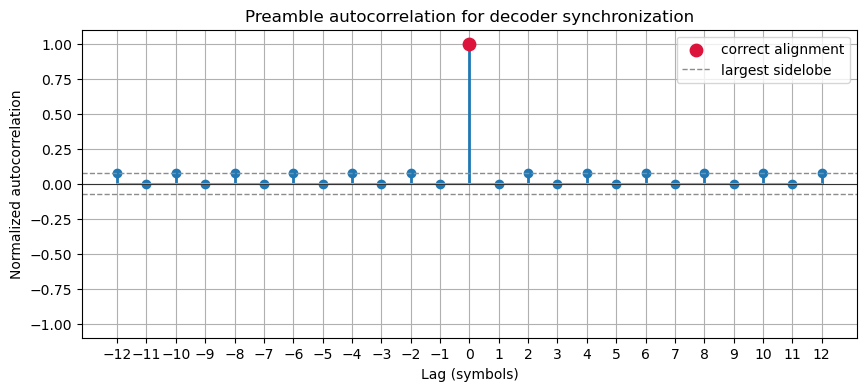

Preamble bits:        1111100110101
Preamble as +/-1:     [ 1  1  1  1  1 -1 -1  1  1 -1  1 -1  1]
Peak at zero lag:     1.00
Largest sidelobe abs: 0.08


In [775]:
preamble_bits = np.asarray(PREAMBLE_BITS, dtype=int)
preamble_pm1 = bits_to_pm1(preamble_bits)

preamble_autocorr = np.correlate(preamble_pm1, preamble_pm1, mode="full")
preamble_lags = np.arange(-(len(preamble_pm1) - 1), len(preamble_pm1))
preamble_autocorr_norm = preamble_autocorr / np.max(np.abs(preamble_autocorr))

zero_lag_idx = np.where(preamble_lags == 0)[0][0]
sidelobes = np.delete(preamble_autocorr_norm, zero_lag_idx)
max_sidelobe = np.max(np.abs(sidelobes)) if len(sidelobes) else 0.0

fig, ax = plt.subplots(figsize=(10, 4))
markerline, stemlines, baseline = ax.stem(
    preamble_lags,
    preamble_autocorr_norm,
    linefmt="tab:blue",
    markerfmt="o",
    basefmt="0.65",
)
plt.setp(markerline, markersize=6)
plt.setp(stemlines, linewidth=2)

ax.scatter([0], [preamble_autocorr_norm[zero_lag_idx]], color="crimson", s=80, zorder=3, label="correct alignment")
ax.axhline(0, color="0.2", linewidth=0.8)
ax.axhline(max_sidelobe, color="0.55", linewidth=1.0, linestyle="--", label="largest sidelobe")
ax.axhline(-max_sidelobe, color="0.55", linewidth=1.0, linestyle="--")
ax.set_xticks(preamble_lags)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel("Lag (symbols)")
ax.set_ylabel("Normalized autocorrelation")
ax.set_title("Preamble autocorrelation for decoder synchronization")
ax.legend(loc="upper right")
plt.show()

print("Preamble bits:       ", ''.join(map(str, preamble_bits)))
print("Preamble as +/-1:    ", preamble_pm1)
print(f"Peak at zero lag:     {preamble_autocorr_norm[zero_lag_idx]:.2f}")
print(f"Largest sidelobe abs: {max_sidelobe:.2f}")

## Compact distortion sweep
Run the current encoder/decoder across a few source files and channel combinations. The table reports only the distortion condition, decoded bits, bit error rate, and signal-to-noise ratio.

In [776]:
import copy
import contextlib
import io
import pandas as pd

sweep_audio_paths = [
    "data/MomAndBald.wav",
    "data/watermark_demo/clean/librispeech_04_speaker_6295_6.8s.wav",
    "data/watermark_demo/clean/librispeech_10_speaker_84_8.2s.wav",
]

sweep_distortions = [
    {"name": "clean", "bandlimit": False, "awgn": False, "resample": False, "quantize": False},
    {"name": "quantize_4bit", "bandlimit": False, "awgn": False, "resample": False, "quantize": True},
    {"name": "awgn", "bandlimit": False, "awgn": True, "resample": False, "quantize": False},
    {"name": "bandlimit", "bandlimit": True, "awgn": False, "resample": False, "quantize": False},
    {"name": "bandlimit_quantize", "bandlimit": True, "awgn": False, "resample": False, "quantize": True},
    {"name": "resample_quantize", "bandlimit": False, "awgn": False, "resample": True, "quantize": True},
    {"name": "bandlimit_awgn_quantize", "bandlimit": True, "awgn": True, "resample": False, "quantize": True},
]

def apply_sweep_distortion(y, fs, combo, rng=None):
    y_out = y.copy()
    if combo["bandlimit"]:
        y_out = apply_bandlimit(y_out, fs)
    if combo["awgn"]:
        y_out = apply_awgn(y_out, NOISE_STD, rng=rng)
    if combo["resample"]:
        y_out, _ = apply_resample_roundtrip(y_out, fs, target_fs=CHANNEL_TARGET_FS)
    if combo["quantize"]:
        y_out = apply_uniform_quantization(y_out, bits=QUANT_BITS)
    return normalize_audio(y_out)

def compact_sweep_start_frame(x_case, fs_case):
    frame_len_case = ms_to_samples(FRAME_MS, fs_case)
    hop_len_case = ms_to_samples(HOP_MS, fs_case)
    total_frames = 1 + max(0, (len(x_case) - frame_len_case) // hop_len_case)
    min_start = int(MIN_EMBED_OFFSET_S * fs_case / hop_len_case)
    packet_len = len(PREAMBLE_BITS) + len(WATERMARK_BITS) * BIT_REPEAT
    max_start = max(0, total_frames - packet_len)
    return int(np.clip(min_start, 0, max_start))

def run_compact_sweep_case(audio_path, combo, file_idx, combo_idx):
    x_case, fs_case = load_audio(audio_path)
    x_case = normalize_audio(x_case)
    start_frame = compact_sweep_start_frame(x_case, fs_case)

    y_wm_case, meta_case = embed_spread_spectrum(
        x=x_case,
        fs=fs_case,
        bits=WATERMARK_BITS,
        frame_ms=FRAME_MS,
        hop_ms=HOP_MS,
        nfft=NFFT,
        f_low=FREQ_LOW,
        f_high=FREQ_HIGH,
        alpha=EMBED_STRENGTH,
        repeat=BIT_REPEAT,
        start_frame=start_frame,
        rng=np.random.default_rng(WATERMARK_KEY_SEED + file_idx),
    )

    y_rx_case = apply_sweep_distortion(
        y_wm_case,
        fs_case,
        combo,
        rng=np.random.default_rng(WATERMARK_KEY_SEED + 100 * file_idx + combo_idx),
    )

    decode_meta = copy.deepcopy(meta_case)
    with contextlib.redirect_stdout(io.StringIO()):
        decoded_bits_case, _, _ = decode_spread_spectrum(
            y=y_rx_case,
            fs=fs_case,
            metadata=decode_meta,
            frame_ms=FRAME_MS,
            hop_ms=HOP_MS,
            nfft=NFFT,
            repeat=BIT_REPEAT,
        )

    decoded_payload = decoded_bits_case[:len(WATERMARK_BITS)]
    return {
        "file": Path(audio_path).name,
        "distortion": combo["name"],
        "ber": bit_error_rate(WATERMARK_BITS, decoded_payload),
        "snr_db": snr_db(x_case, y_rx_case),
        "decoded_bits": ''.join(str(int(b)) for b in decoded_payload),
    }

sweep_rows = []
for file_idx, audio_path in enumerate(sweep_audio_paths):
    if not Path(audio_path).exists():
        print(f"Skipping missing file: {audio_path}")
        continue
    for combo_idx, combo in enumerate(sweep_distortions):
        sweep_rows.append(run_compact_sweep_case(audio_path, combo, file_idx, combo_idx))

compact_sweep_results = pd.DataFrame(sweep_rows)
compact_sweep_results["ber"] = compact_sweep_results["ber"].round(3)
compact_sweep_results["snr_db"] = compact_sweep_results["snr_db"].round(2)
display(compact_sweep_results)


Embed packet starts:
  packet 0: start_frame=50, start_time=0.500s
  packet 1: start_frame=95, start_time=0.950s
  packet 2: start_frame=140, start_time=1.400s
  packet 3: start_frame=185, start_time=1.850s
  packet 4: start_frame=230, start_time=2.300s
  packet 5: start_frame=275, start_time=2.750s
  packet 6: start_frame=320, start_time=3.200s
  packet 7: start_frame=365, start_time=3.650s
  packet 8: start_frame=410, start_time=4.100s
  packet 9: start_frame=455, start_time=4.550s
  packet 10: start_frame=500, start_time=5.000s
  packet 11: start_frame=545, start_time=5.450s
  packet 12: start_frame=590, start_time=5.900s
Embed packet starts:
  packet 0: start_frame=50, start_time=0.500s
  packet 1: start_frame=95, start_time=0.950s
  packet 2: start_frame=140, start_time=1.400s
  packet 3: start_frame=185, start_time=1.850s
  packet 4: start_frame=230, start_time=2.300s
  packet 5: start_frame=275, start_time=2.750s
  packet 6: start_frame=320, start_time=3.200s
  packet 7: start_f

,file,distortion,ber,snr_db,decoded_bits
0,MomAndBald.wav,clean,0.000,11.58,11001100
1,MomAndBald.wav,quantize_4bit,0.125,4.91,11001000
2,MomAndBald.wav,awgn,0.000,11.45,11001100
3,MomAndBald.wav,bandlimit,0.000,-1.76,11001100
4,MomAndBald.wav,bandlimit_quantize,0.000,-2.46,11001100
5,MomAndBald.wav,resample_quantize,0.000,4.80,11001100
6,MomAndBald.wav,bandlimit_awgn_quantize,0.000,-2.46,11001100
7,librispeech_04_speaker_6295_6.8s.wav,clean,0.125,20.46,11001000
8,librispeech_04_speaker_6295_6.8s.wav,quantize_4bit,0.125,7.77,11101100
9,librispeech_04_speaker_6295_6.8s.wav,awgn,0.125,19.60,11001000
